# A1

In [2]:
weight_decay = 0.01
max_epoch = 100
batch_size = 128
patience = 5
initial_lr = 0.001

In [3]:
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [4]:
import common_utils
import pandas as pd

common_utils.set_seed()
df = pd.read_csv(r"C:\Users\kyeyo\OneDrive\Desktop\SC4001\Individual Assignment\files_PartA\files_PartA\audio_gtzan.csv")
display(df.head())

,filename,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,rolloff_mean,...,mfcc16_mean,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var
0,blues.00000.0.wav,0.335406,0.091048,0.130405,0.003521,1773.065032,167541.630869,1972.744388,117335.771563,3714.560359,...,-2.853603,39.687145,-3.241280,36.488243,0.722209,38.099152,-5.050335,33.618073,-0.243027,43.771767
1,blues.00000.1.wav,0.343065,0.086147,0.112699,0.001450,1816.693777,90525.690866,2010.051501,65671.875673,3869.682242,...,4.074709,64.748276,-6.055294,40.677654,0.159015,51.264091,-2.837699,97.030830,5.784063,59.943081
2,blues.00000.2.wav,0.346815,0.092243,0.132003,0.004620,1788.539719,111407.437613,2084.565132,75124.921716,3997.639160,...,4.806280,67.336563,-1.768610,28.348579,2.378768,45.717648,-1.938424,53.050835,2.517375,33.105122
3,blues.00000.3.wav,0.363639,0.086856,0.132565,0.002448,1655.289045,111952.284517,1960.039988,82913.639269,3568.300218,...,-1.359111,47.739452,-3.841155,28.337118,1.218588,34.770935,-3.580352,50.836224,3.630866,32.023678
4,blues.00000.4.wav,0.335579,0.088129,0.143289,0.001701,1630.656199,79667.267654,1948.503884,60204.020268,3469.992864,...,2.092937,30.336359,0.664582,45.880913,1.689446,51.363583,-3.392489,26.738789,0.536961,29.146694


In [5]:
test_size = int(len(df)/4)
train_size = len(df) - test_size

# Add class column
df['label'] = 0  # default to 0
df.loc[df['filename'].str.startswith('metal'), 'label'] = 1

df_train_unscaled, y_train, df_test_unscaled, y_test = common_utils.split_dataset(df, ["filename", "label"], test_size, 0)

nd_train, nd_test = common_utils.preprocess_dataset(df_train_unscaled, df_test_unscaled)

from torch.utils.data import DataLoader
# may not use the conversion in AudioDataset, must convert to tensor manually due to audiodataset handling tensors and dataframes but not numpy arrays given by other methods in common utils
train_load = DataLoader(common_utils.AudioDataset(nd_train,
    torch.tensor(y_train.reshape(-1, 1), dtype=torch.float32))
    , batch_size = batch_size)
test_load = DataLoader(common_utils.AudioDataset(nd_test,
    torch.tensor(y_test.reshape(-1, 1), dtype=torch.float32))
    , batch_size = batch_size)


In [6]:
y_train

array([1, 0, 1, ..., 1, 0, 0], dtype=int64)

In [7]:
import torch
import torch.nn as nn

model = common_utils.MLP()
loss_fn = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), weight_decay=weight_decay, lr = initial_lr)
early_stopper = common_utils.EarlyStopper(patience = 5)

In [8]:
def train_loop(dataloader, model, loss_fn, optimizer):
    train_loss= 0
    for _batch, (X, Y) in enumerate(dataloader):
        pred = model(X)
        loss = loss_fn(pred, Y)

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
    return train_loss

def test_loop(dataloader, model, loss_fn):
    test_loss = 0
    with torch.no_grad():
        for X, y in dataloader:
            pred = model(X)
            test_loss += loss_fn(pred, y).item()
    return test_loss

In [9]:
train_losses = []
test_losses = []
epochs = []

for epoch in range(max_epoch):
    train_loss = train_loop(train_load, model, loss_fn, optimizer)
    test_loss = test_loop(test_load, model, loss_fn)

    train_losses.append(train_loss)
    test_losses.append(test_loss)
    epochs.append(epoch)

    if early_stopper.early_stop(test_loss):
        break

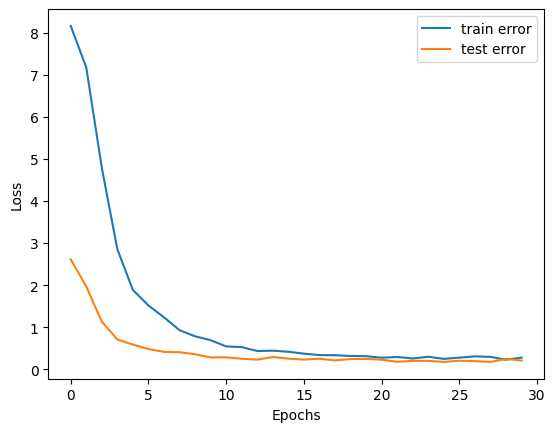

In [10]:
import matplotlib.pyplot as plt 
import numpy as np

plt.plot(epochs, train_losses, label= "train error")
plt.plot(epochs, test_losses, label= "test error")
plt.title = "BCE Loss vs Epoch"
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

In [11]:
import shap
features = common_utils.extract_features(r"C:\Users\kyeyo\OneDrive\Desktop\SC4001\Individual Assignment\files_PartA\files_PartA\audio_test.wav")
features.drop(labels = ["filename"], axis=1, inplace=True)
# display(features)
features = torch.tensor(features.to_numpy().astype(np.float32), dtype = torch.float)

background_data = 0
for X_batch, Y_batch in train_load:
    background_data = X_batch  
    break  # Take only the first batch

explainer = shap.DeepExplainer(model, background_data)
shap_values = explainer(features)
shap_array = shap_values.values  

# Remove singleton axes
shap_array = np.squeeze(shap_array)   # → shape: (n_features,)

# Mean absolute shap value per feature
feature_importance = np.abs(shap_array)  # absolute SHAP values

# Get top 5 indices
top5_indices = np.argsort(feature_importance)[-5:][::-1]
print("Top 5 Feature Indices:", top5_indices)

print("Top 5 SHAP Values:", feature_importance[top5_indices])

# Map to feature names
feature_names = df.columns[1:]  # ensure these match the 57 features
top5_names = [feature_names[i] for i in top5_indices]
print("Top 5 influential features:", top5_names)

Top 5 Feature Indices: [9 7 5 8 4]
Top 5 SHAP Values: [0.40476352 0.08182067 0.05528307 0.00801922 0.00435503]
Top 5 influential features: ['rolloff_var', 'spectral_bandwidth_var', 'spectral_centroid_var', 'rolloff_mean', 'spectral_centroid_mean']


# Q2

In [20]:
no_folds = 5
fold_size = int(1000/ no_folds)
lr_list = [0.0001, 0.0005, .0001, .0005, .01]

In [24]:
from sklearn import preprocessing

label_encoder = preprocessing.LabelEncoder()
standard_scaler = preprocessing.StandardScaler()

df_cpy = df.copy()
df_cpy['label'] = label_encoder.fit_transform(df_cpy['label'])
nd_X = df_cpy.drop(["filename", "label"], axis = 1).to_numpy()
nd_Y = df_cpy["label"].to_numpy().reshape(-1, 1)
nd_X = standard_scaler.fit_transform(nd_X)

In [ ]:
from sklearn.metrics import roc_auc_score
import time 

# initialize dicts; will fill this in based on performance later
X_train_scaled_dict, X_val_scaled_dict, y_train_dict, y_val_dict = {}, {}, {}, {}
for lr in lr_list:
    X_train_scaled_dict[lr] = []
    X_val_scaled_dict[lr] = []
    y_train_dict[lr] = []
    y_val_dict[lr] = []

def train(X, Y):
    # Use an object-typed numpy array so we can store mixed objects (arrays/scalars/dicts).
    performance = np.empty((no_folds, len(lr_list), 2), dtype=object)
    for fold in range(no_folds):
        start_idx, end_idx = fold * fold_size, (fold + 1) * fold_size
        x_test, y_test = X[start_idx:end_idx], Y[start_idx:end_idx]
        x_train = np.concatenate((X[:start_idx], X[end_idx:]), axis=0) if start_idx > 0 or end_idx < len(X) else X.copy()
        y_train = np.concatenate((Y[:start_idx], Y[end_idx:]), axis=0) if start_idx > 0 or end_idx < len(Y) else Y.copy()

        fold_start_time = time.time()
        # enumerate lr_list so we use integer indices into the ndarray
        for lr_idx, lr in enumerate(lr_list):
            model = common_utils.MLP()
            loss_fn = nn.BCELoss()
            optimizer = torch.optim.SGD(model.parameters(), lr=lr)
            early_stopper = common_utils.EarlyStopper(patience=patience, min_delta=0)

            epoch = 0
            pred_train = None
            pred_test = None
            train_loss = None
            test_loss = None

            for epoch in range(max_epoch):
                model.train()
                inputs = torch.tensor(x_train, dtype=torch.float)
                targets = torch.tensor(y_train, dtype=torch.float)
                pred_train = model(inputs)
                train_loss = loss_fn(pred_train, targets)

                optimizer.zero_grad()
                train_loss.backward()
                optimizer.step()

                model.eval()
                with torch.no_grad():
                    pred_test = model(torch.tensor(x_test, dtype=torch.float))
                    test_loss = loss_fn(pred_test, torch.tensor(y_test, dtype=torch.float))

                if early_stopper.early_stop(test_loss):
                    break

            fold_end_time = time.time()

            # Convert tensors to numpy 1-D arrays (ravel) and scalars where appropriate
            pred_train_np = pred_train.detach().cpu().numpy().ravel() if isinstance(pred_train, torch.Tensor) else np.ravel(pred_train)
            pred_test_np = pred_test.detach().cpu().numpy().ravel() if isinstance(pred_test, torch.Tensor) else np.ravel(pred_test)
            y_train_np = np.ravel(y_train)
            y_test_np = np.ravel(y_test)

            # Safe AUC computation: if only one class present, roc_auc_score will fail
            try:
                auc_train = float(roc_auc_score(y_train_np, pred_train_np))
            except Exception:
                auc_train = float('nan')
            try:
                auc_test = float(roc_auc_score(y_test_np, pred_test_np))
            except Exception:
                auc_test = float('nan')

            # Store dictionaries (mixed types) into the object array
            perf_train = {
                'pred': pred_train_np,
                'loss': float(train_loss.item()) if hasattr(train_loss, 'item') else float(train_loss),
                'auc': auc_train,
                'time': fold_end_time - fold_start_time,
                'epoch': int(epoch)
            }
            perf_test = {
                'pred': pred_test_np,
                'loss': float(test_loss.item()) if hasattr(test_loss, 'item') else float(test_loss),
                'auc': auc_test,
                'time': fold_end_time - fold_start_time,
                'epoch': int(epoch)
            }

            performance[fold, lr_idx, 0] = perf_train
            performance[fold, lr_idx, 1] = perf_test
    return performance

In [32]:
performance = train(nd_X, nd_Y)

IndexError: only integers, slices (`:`), ellipsis (`...`), numpy.newaxis (`None`) and integer or boolean arrays are valid indices

In [ ]:
performance

array([[[[0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0.]],

        [[0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0.]],

        [[0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0.]],

        [[0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0.]],

        [[0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0.]]],


       [[[0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0.]],

        [[0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0.]],

        [[0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0.]],

        [[0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0.]],

        [[0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0.]]],


       [[[0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0.]],

        [[0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0.]],

        [[0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0.]],

        [[0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0.]],

        [[0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0.]]],


       [[[0., 0., 0., 0., 0.],
   